<center><h1>Wagner_Anton_HW4</h1></center>
<br>
<br>

Name: Anton Wagner
<br>
Github Username: AntonW1
<br>
USC ID: 2245157283

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
import re
from sklearn.feature_selection import RFE
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import statsmodels.api as sm
from sklearn.metrics import confusion_matrix, roc_curve, auc, accuracy_score
import warnings
warnings.simplefilter('ignore')
from sklearn.preprocessing import label_binarize # for multiclass ROC
from sklearn.naive_bayes import GaussianNB, MultinomialNB # part 2c ii

In [2]:
np.random.seed(0)

Get the AReM Data Set

In [3]:
data_path = '../Homework 3, 4 Data/AReM'

data = {}
columns = ['time', 'avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']
time_series_only = ['avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']
failed_files = []

for action in os.listdir(data_path):
    file_path = data_path + '/' + action
    if os.path.isdir(file_path):
        for dataset_name in os.listdir(file_path):
            dataset_path = file_path + '/' + dataset_name
            dataset_number = int(re.findall(r'\d+', dataset_name)[0])
            try:
                dataset = pd.read_csv(dataset_path, names=columns, usecols=range(7), header=None, comment='#', sep=r'[,\s]+', engine='python')
                data[(action, dataset_number)] = dataset
            except pd.errors.ParserError:
                failed_files.append(dataset_path)

print(f"Files read successfully: {len(data)}")
print(failed_files)

Files read successfully: 88
[]


### (b) Splitting Data

In [4]:
train_test_split = {}

for (action, dataset_number) in data:
    test_dataset_numbers = []
    if action in ['bending1', 'bending2']:
        test_dataset_numbers = [1, 2]
    else:
        test_dataset_numbers = [1, 2, 3]

    if dataset_number in test_dataset_numbers:
        train_test_split[(action, dataset_number)] = 'test'
    else:
        train_test_split[(action, dataset_number)] = 'train'


print(pd.Series(train_test_split).value_counts())

train    69
test     19
Name: count, dtype: int64


### (c) Feature Extraction

In [5]:
rows = []

for (action, dataset_number), dataset in data.items():
    row = {'activity': action, 'file': dataset_number, 'split': train_test_split[(action, dataset_number)]}
    for column in columns[1:]:
        time_series = dataset[column]
        row['min_' + column] = time_series.min()
        row['max_' + column] = time_series.max()
        row['mean_' + column] = time_series.mean()
        row['median_' + column] = time_series.median()
        row['q1_' + column] = time_series.quantile(0.25)
        row['q3_' + column] = time_series.quantile(0.75)
        row['std_' + column] = time_series.std()
        
    rows.append(row)

features = pd.DataFrame(rows)
print(features.shape)
features.head(10)

(88, 45)


,activity,file,split,min_avg_rss12,max_avg_rss12,mean_avg_rss12,median_avg_rss12,q1_avg_rss12,q3_avg_rss12,std_avg_rss12,...,q1_avg_rss23,q3_avg_rss23,std_avg_rss23,min_var_rss23,max_var_rss23,mean_var_rss23,median_var_rss23,q1_var_rss23,q3_var_rss23,std_var_rss23
0,bending1,1,test,37.25,45.00,40.624792,40.50,39.2500,42.00,1.476967,...,33.0000,36.00,2.188449,0.0,1.92,0.570583,0.43,0.00,1.30,0.582915
1,bending1,2,test,38.00,45.67,42.812812,42.50,42.0000,43.67,1.435550,...,32.0000,34.50,1.995255,0.0,3.11,0.571083,0.43,0.00,1.30,0.601010
2,bending1,3,train,35.00,47.40,43.954500,44.33,43.0000,45.00,1.558835,...,35.3625,36.50,1.999604,0.0,1.79,0.493292,0.43,0.00,0.94,0.513506
3,bending1,4,train,33.00,47.75,42.179812,43.50,39.1500,45.00,3.670666,...,30.4575,36.33,3.849448,0.0,2.18,0.613521,0.50,0.00,1.00,0.524317
4,bending1,5,train,33.00,45.75,41.678063,41.75,41.3300,42.75,2.243490,...,28.4575,31.25,2.411026,0.0,1.79,0.383292,0.43,0.00,0.50,0.389164
5,bending1,6,train,37.00,48.00,43.454958,43.25,42.5000,45.00,1.386098,...,22.2500,24.00,2.488862,0.0,5.26,0.679646,0.50,0.43,0.87,0.622534
6,bending1,7,train,36.25,48.00,43.969125,44.50,43.3100,44.67,1.618364,...,20.5000,23.75,3.318301,0.0,2.96,0.555312,0.49,0.00,0.83,0.487826
7,bending2,1,test,12.75,51.00,24.562958,24.25,23.1875,26.50,3.737514,...,20.5000,27.00,3.693786,0.0,4.97,0.700188,0.50,0.43,0.87,0.693720
8,bending2,2,test,0.00,42.75,27.464604,28.00,25.5000,30.00,3.583582,...,15.0000,20.75,5.053642,0.0,6.76,1.122125,0.83,0.47,1.30,1.012342
9,bending2,3,train,21.00,50.00,32.586208,33.00,26.1875,34.50,6.238143,...,17.6700,23.50,5.032424,0.0,13.61,1.162042,0.83,0.47,1.30,1.332980


From my analysis in HW3:

I am selecting **mean**, **3rd quartile**, as well as **standard deviation** as the most important time-domain features.
I used an ANOVA F-score test to investigate how well each of the features separate the activities and then averaged them across the 6 time series. Mean (368.2) and 3rd quartile (350.4) were selected as they have the highest scores. I also chose standard deviation because I believe the signal spread provides meaningful information that the other two features do not capture. Although median and 1st quartile had higher scores than std, they may be more correlated with mean and 3rd quartile and thus not provide as much extra insight.

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

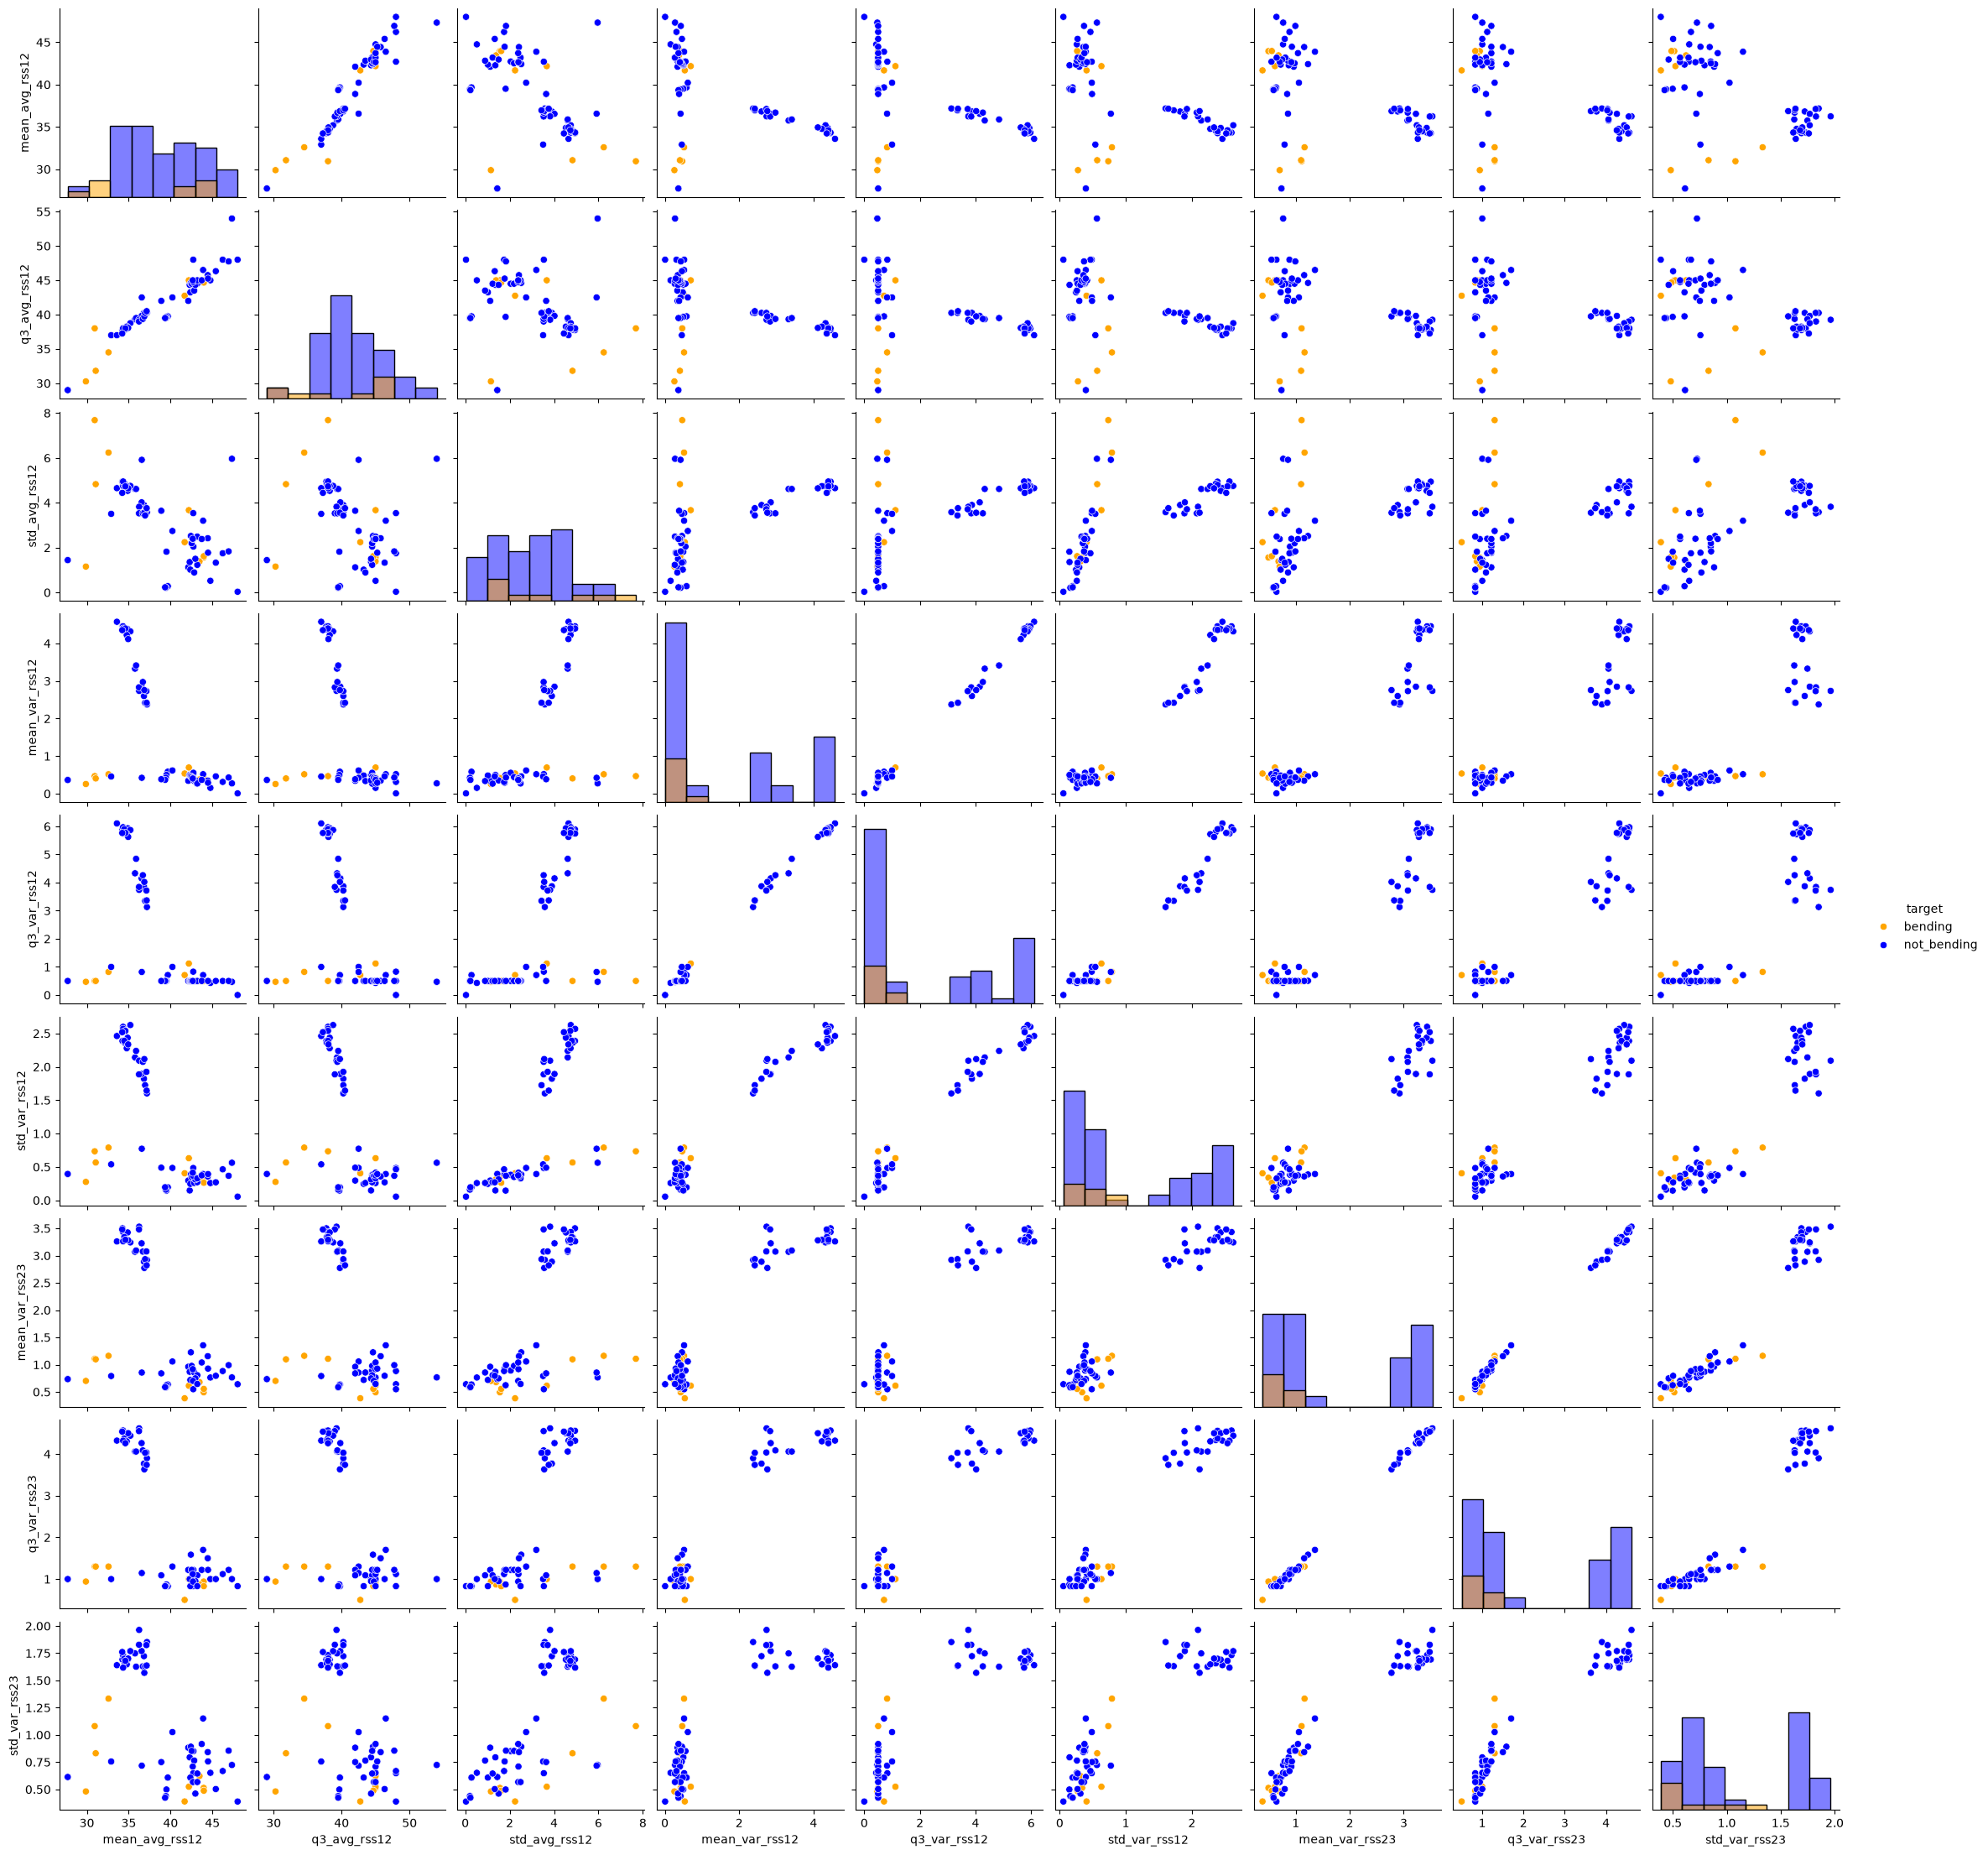

In [6]:
training_set = features[features['split'] == 'train'].copy()

training_set['target'] = np.where(training_set['activity'].isin(['bending1', 'bending2']), 'bending', 'not_bending')

time_series = ['avg_rss12', 'var_rss12', 'var_rss23']
chosen_features = ['mean', 'q3', 'std']
plot_columns = [f'{metric}_{series}' for series in time_series for metric in chosen_features]

sns.pairplot(training_set[plot_columns + ['target']], diag_kind='hist', hue='target', palette={'bending': 'orange', 'not_bending': 'blue'})
plt.show()

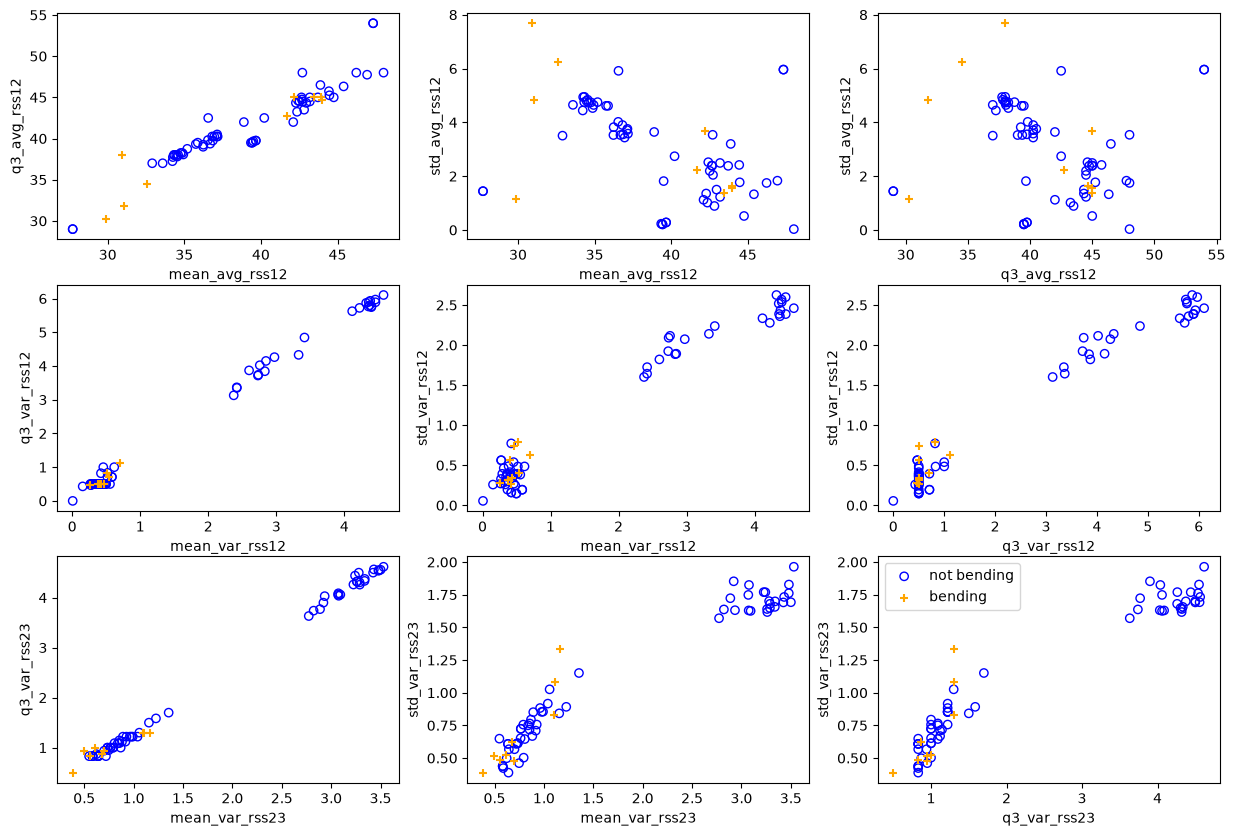

In [7]:
# For better visibility, in addition to the 9x9, I also made a 3x3 as suggested by Piazza @102f2

bending = training_set[training_set['target'] == 'bending']
not_bending = training_set[training_set['target'] == 'not_bending']

pairs = [('mean', 'q3'), ('mean', 'std'), ('q3', 'std')]

fig, axes = plt.subplots(3,3, figsize=(15,10))

for i in range(3):
    for j in range(3):
        series = time_series[i]
        x = pairs[j][0] + '_' + series
        y = pairs[j][1] + '_' + series

        axes[i, j].scatter(not_bending[x], not_bending[y], label='not bending', facecolors='none', edgecolors='blue')
        axes[i, j].scatter(bending[x], bending[y], label='bending', marker='+', color='orange')
        axes[i, j].set_xlabel(x)
        axes[i, j].set_ylabel(y)

plt.legend()
plt.show()

For the chosen features, it seems like bending largely overlaps with the other activities, although there is some distinction in the avg_rss12 set.

#### ii. Splitted Plots

In [8]:
print([len(d) for d in data.values()])

[480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 479, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480, 480]


All except for one have 480 rows, so 240 is a good midpoint.

In [9]:
rows = []

for (action, number), dataset in data.items():
    if train_test_split[(action, number)] != 'train':
        continue
    row = {'activity': action}
    for ts in time_series_only:
        values = dataset[ts]
        half_1 = values[:240]
        half_2 = values[240:]

        row['mean_' + ts + '_1'] = half_1.mean()
        row['q3_' + ts + '_1'] = half_1.quantile(0.75)
        row['std_' + ts + '_1'] = half_1.std()

        row['mean_' + ts + '_2'] = half_2.mean()
        row['q3_' + ts + '_2'] = half_2.quantile(0.75)
        row['std_' + ts + '_2'] = half_2.std()

    rows.append(row)

split_features = pd.DataFrame(rows)
split_features['target'] = np.where(split_features['activity'].isin(['bending1', 'bending2']), 'bending', 'not_bending')

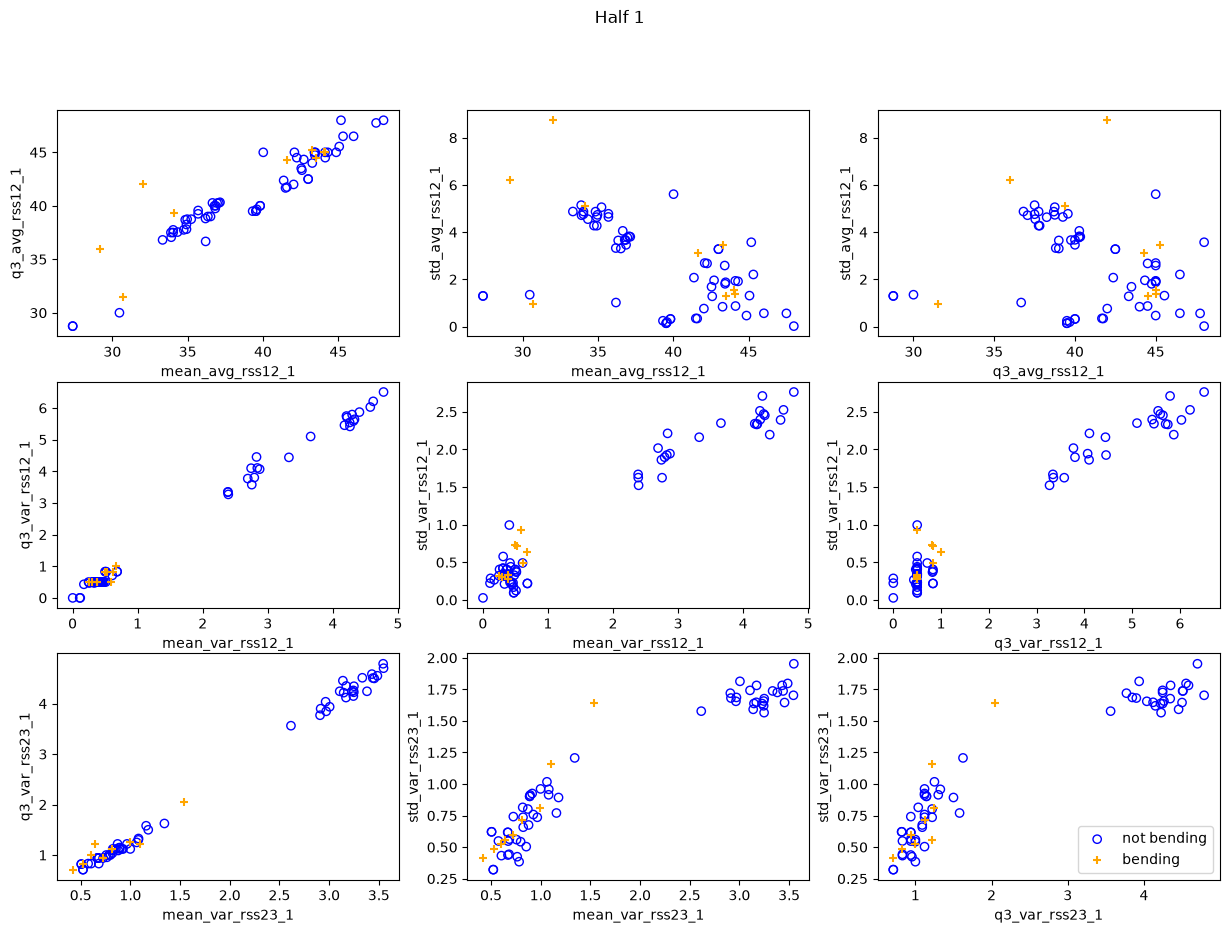

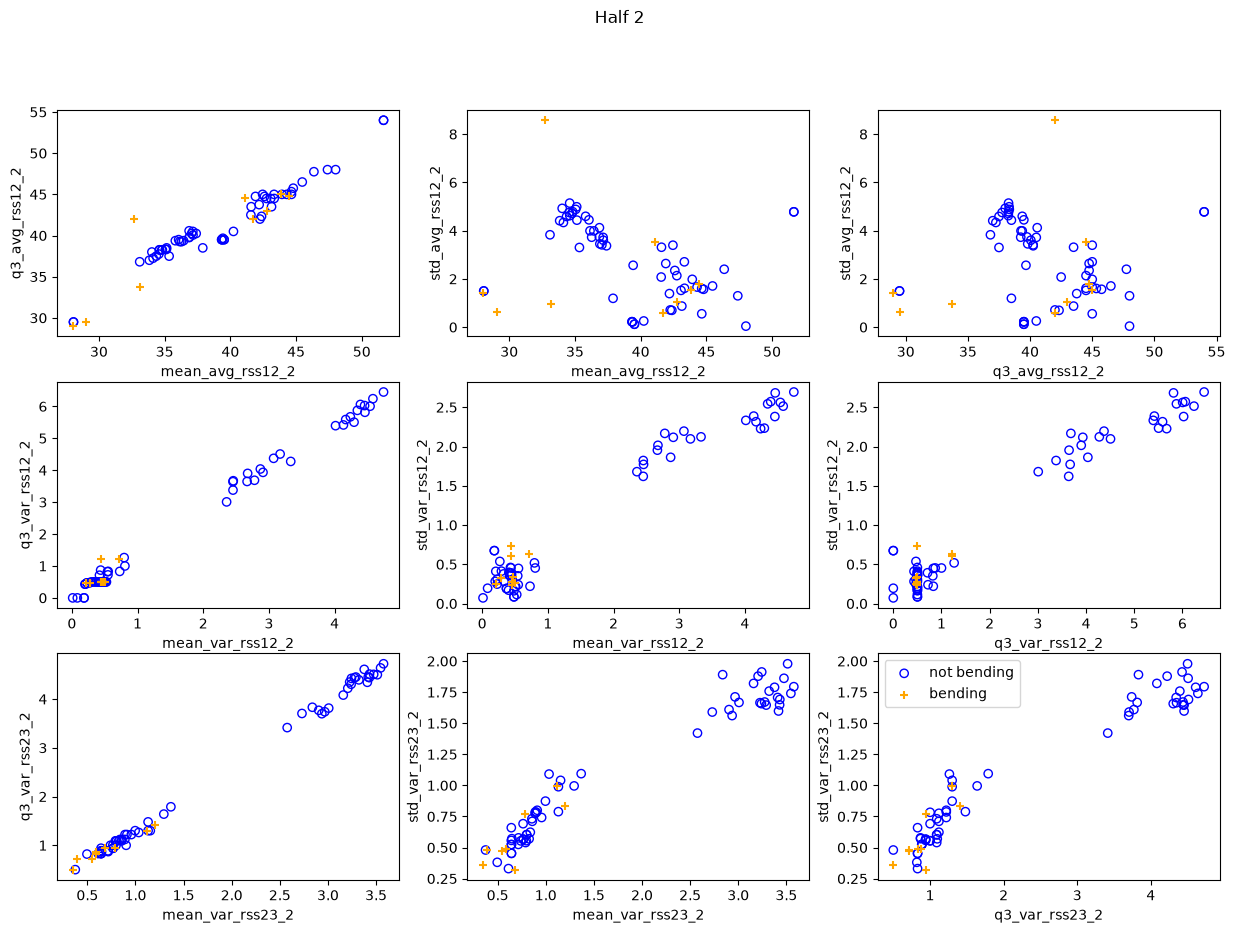

In [10]:
bending = split_features[split_features['target'] == 'bending']
not_bending = split_features[split_features['target'] == 'not_bending']

for half in [1, 2]:
    fig, axes = plt.subplots(3, 3, figsize=(15, 10))
    fig.suptitle(f'Half {half}')

    for i in range(3):
        for j in range(3):
            series = time_series[i]
            x = pairs[j][0] + '_' + series + '_' + str(half)
            y = pairs[j][1] + '_' + series + '_' + str(half)

            axes[i, j].scatter(not_bending[x], not_bending[y], label='not bending', facecolors='none', edgecolors='blue')
            axes[i, j].scatter(bending[x], bending[y], label='bending', marker='+', color='orange')
            axes[i, j].set_xlabel(x)
            axes[i, j].set_ylabel(y)

    plt.legend()
    plt.show()

Dividing the series in half did not noticeably impact the appearance. Bending and non-bending activities still largely overlap each other. The avg_rss12 series is still slightly more separated. It seems a bit noisier with half the data, but I don't think there is a considerable difference from part a.

#### iii. Time Series Segments

In [11]:
def split_series(l, split_set):
    rows = []
    for (action, number), dataset in data.items():
        if train_test_split[(action, number)] != split_set:
            continue
        row = {'activity': action}
        for ts in time_series_only:
            l_pieces = np.array_split(dataset[ts], l)
            for i in range(l):
                piece = pd.Series(l_pieces[i])
                row[f'mean_{ts}_{i+1}'] = piece.mean()
                row[f'q3_{ts}_{i+1}'] = piece.quantile(0.75)
                row[f'std_{ts}_{i+1}'] = piece.std()
        rows.append(row)
    df = pd.DataFrame(rows)
    x = df.drop(columns=['activity'])
    y = np.where(df['activity'].isin(['bending1', 'bending2']), 1, 0)
    return x, y

In [12]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
p_features = [1, 2, 3, 5, 10, 15, 20, 30, 50, 100]

results = []

for l in range(1, 21):
    x, y = split_series(l, 'train') # still just using the training set

    for p in p_features:
        if p > x.shape[1]:
            continue

        per_fold_accuracy = []

        for train_index, value_index in folds.split(x, y):
            # split into new training folds and the cross validation test fold
            x_train, x_value = x.iloc[train_index], x.iloc[value_index]
            y_train, y_value = y[train_index], y[value_index]

            # RFE to find the p best features
            model = LogisticRegression(C=999999999, max_iter=1000) # C=999999999 as footnote 3 recommends setting it to a very large number
            rfe = RFE(model, n_features_to_select=p, step=0.1)
            rfe = rfe.fit(x_train, y_train)
            x_train_p = x_train.iloc[:, rfe.support_]
            x_value_p = x_value.iloc[:, rfe.support_]

            real_model = LogisticRegression(C=999999999, max_iter=1000)
            real_model.fit(x_train_p, y_train)
            accuracy = (real_model.predict(x_value_p) == y_value).mean()
            per_fold_accuracy.append(accuracy)

        results.append((l, p, np.mean(per_fold_accuracy)))

results_df = pd.DataFrame(results, columns=['l', 'p', 'cv_accuracy'])
print(results_df.sort_values('cv_accuracy', ascending=False))

      l    p  cv_accuracy
16    3    3     1.000000
39    5   30     0.985714
38    5   20     0.985714
90   10  100     0.985714
150  16  100     0.985714
..   ..  ...          ...
34    5    3     0.897802
51    7    1     0.884615
74    9    5     0.870330
0     1    1     0.870330
101  12    1     0.869231

[191 rows x 3 columns]


In [13]:
best_l = 3
best_p = 3

x_train, y_train = split_series(best_l, 'train')

model = LogisticRegression(C=999999999, max_iter=1000)
rfe = RFE(model, n_features_to_select=best_p, step=0.1)
rfe = rfe.fit(x_train, y_train)

best_columns = x_train.columns[rfe.support_]
x_train_best = x_train[best_columns]
print(best_columns)

Index(['q3_avg_rss12_2', 'mean_avg_rss23_1', 'q3_avg_rss23_1'], dtype='str')


I used RFE instead of p-value pruning like the instructions suggested. I found the best pair to be (l, p) = (3, 3) with a 5-fold cross-validation accuracy of 1.0.

I used StratifiedKFold since the classes are out of balance. With only 9 bending samples, there would likely only be 1 or 2 bending in each fold which would severely impact training. StratifiedKFold mitigates this issue.

The six series were split into l pieces (1-20) with 3 features (mean, 3rd quartile, std) so there were 18 * l possible features before RFE reduced it to 3. I searched p over the range 1, 2, 3, 5, 10, 15, 20, 30, 50, 100.

I set C to 999999999 (very large number) to remove L2 regularization as recommended by footnote 3.

The wrong way would be to pick the best p features by running RFE on the training set and then cross-validating a model with those features. This causes an information leak as the feature selection saw all the labels before they are separated into folds.
The right way is to first split the folds and then select the features using RFE within each fold. Fit the model on only the training folds and score with the validation fold. Repeating this for all five folds.

#### iv. Confusion Matrix

In [14]:
# using Logit Regression with the statsmodel package
x_with_constant = sm.add_constant(x_train_best)
model_logit = sm.Logit(y_train, x_with_constant).fit(maxiter=100)
coefficients = pd.DataFrame({'coefficient': model_logit.params, 'p_value': model_logit.pvalues})
print(model_logit.summary())

         Current function value: 0.000000
         Iterations: 100
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                   69
Model:                          Logit   Df Residuals:                       65
Method:                           MLE   Df Model:                            3
Date:                Thu, 22 Oct 2026   Pseudo R-squ.:                   1.000
Time:                        23:30:27   Log-Likelihood:            -2.3678e-10
converged:                      False   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                 1.481e-11
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const             -131.3433   4.72e+08  -2.78e-07      1.000   -9.25e+08    9.25e+08
q3_avg_rss12_2      -8.4583   2.24e+07  -3.77e

In [15]:
predicted_probability = model_logit.predict(x_with_constant)
predicted_class = np.where(predicted_probability >= 0.5, 1, 0)
pretty_confusion_matrix = pd.DataFrame(confusion_matrix(y_train, predicted_class),columns=['Predicted 0', 'Predicted 1'], index=['Actual 0 (Not bending)', 'Actual 1 (Bending)'])
pretty_confusion_matrix.index.name = f'l* = {best_l}, p* = {best_p}'
pretty_confusion_matrix
# confusion matrix in the style of the homework 1 grading

,Predicted 0,Predicted 1
"l* = 3, p* = 3",,
Actual 0 (Not bending),60,0
Actual 1 (Bending),0,9


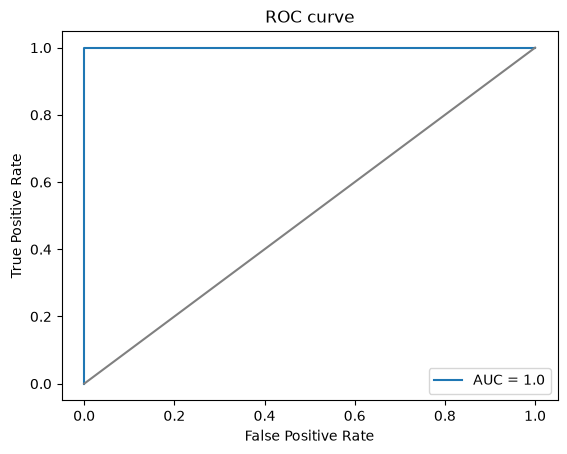

In [16]:
false_positive_rate, true_positive_rate, thresholds = roc_curve(y_train, predicted_probability)
area_under_curve = auc(false_positive_rate, true_positive_rate)
plt.plot(false_positive_rate, true_positive_rate, label='AUC = ' + f'{round(area_under_curve, 3)}')
plt.plot([0, 1], [0, 1], color='gray')
plt.legend()
plt.title('ROC curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

In [17]:
print(coefficients)

                  coefficient  p_value
const             -131.343289      1.0
q3_avg_rss12_2      -8.458322      1.0
mean_avg_rss23_1     9.438571      1.0
q3_avg_rss23_1      11.895906      1.0


The model classifies all 69 instances of the training set correctly so the AUC is 1.0. This was 9 bending and 60 not bending. Because the three features separate the classes perfectly, statsmodel goes to the iteration limit and stops without converging. This means that the coefficients as not unique estimates and their standard errors are very large. Every p-value is 1.0 so it can't be used for judging the importance of features.

#### v. Test Classifier

In [18]:
x_test, y_test = split_series(best_l, 'test')
x_test_best = x_test[best_columns]
x_test_with_constant = sm.add_constant(x_test_best, has_constant='add')

test_probability = model_logit.predict(x_test_with_constant)
test_class = np.where(test_probability >= 0.5, 1, 0)

test_accuracy = accuracy_score(y_test, test_class)
print('Accuracy on the test set:', test_accuracy)

Accuracy on the test set: 1.0


In [19]:
# confusion matrix comparison
test_confusion_matrix = pd.DataFrame(confusion_matrix(y_test, test_class),columns=['Predicted 0', 'Predicted 1'], index=['Actual 0 (Not bending)', 'Actual 1 (Bending)'])
test_confusion_matrix.index.name = f'l* = {best_l}, p* = {best_p}'
test_confusion_matrix

,Predicted 0,Predicted 1
"l* = 3, p* = 3",,
Actual 0 (Not bending),15,0
Actual 1 (Bending),0,4


The test accuracy is 1.0 which is the same as the cross-validation accuracy. This seems like a strong model, however the test set is fairly small with just 19 samples.

#### vi. Separation

Yes, through analysis with the statsmodels package complete separation and non-convergence  was found using the three features: **q3_avg_rss12_2**, **mean_avg_rss23_1**, and **q3_avg_rss23_1**. The model classifies bending vs not bending perfectly for both the test and training set. This separation is causing instability in the parameters as they will be decided by where the optimizer stops. The p-values are 1.0 and the log likelihood is very close to zero, but this is not meaningful due to the perfect prediction.

#### vii. Imbalance

In [20]:
print(pd.Series(y_train).value_counts())

0    60
1     9
Name: count, dtype: int64


Yes, this dataset is unbalanced. There are 60 non-bending and only 9 bending.

In [21]:
training_data = x_train_best.copy()
training_data['bending'] = y_train
bending_cases = training_data[training_data['bending'] == 1]
not_bending_cases = training_data[training_data['bending'] == 0]

# sample for balanced classes
sampled_controls = not_bending_cases.sample(n=len(bending_cases), random_state=0)
balanced_data = pd.concat([bending_cases, sampled_controls])

x_balanced = balanced_data[best_columns]
y_balanced = balanced_data['bending']

x_balanced_with_constant = sm.add_constant(x_balanced)
balanced_model = sm.Logit(y_balanced, x_balanced_with_constant).fit(maxiter=100)


# intercept needs to be adjusted
real_bending_share = y_train.mean()
real_portion = real_bending_share / (1 - real_bending_share)
sample_portion = 0.5 / (1 - 0.5)
parameter_adjustment = np.log(real_portion) - np.log(sample_portion)
coefficients_adjusted = balanced_model.params.copy()
coefficients_adjusted['const'] = coefficients_adjusted['const'] + parameter_adjustment

print(f'parameter adjustment: {round(parameter_adjustment, 3)}')
print(coefficients_adjusted)

Optimization terminated successfully.
         Current function value: -0.000000
         Iterations 27
parameter adjustment: -1.897
const              -30.031338
q3_avg_rss12_2     -12.729422
mean_avg_rss23_1    14.995739
q3_avg_rss23_1      10.567904
dtype: float64


In [22]:
log_odds = x_with_constant.dot(coefficients_adjusted)

balanced_probability = 1 / (1 + np.exp(-log_odds))
balanced_class = np.where(balanced_probability >= 0.5, 1, 0)
pretty_balanced_confusion_matrix = pd.DataFrame(confusion_matrix(y_train, balanced_class), columns=['Predicted 0', 'Predicted 1'], index=['Actual 0 (Not bending)', 'Actual 1 (Bending)'])
pretty_balanced_confusion_matrix.index.name = f'l* = {best_l}, p* = {best_p}'
pretty_balanced_confusion_matrix

,Predicted 0,Predicted 1
"l* = 3, p* = 3",,
Actual 0 (Not bending),60,0
Actual 1 (Bending),0,9


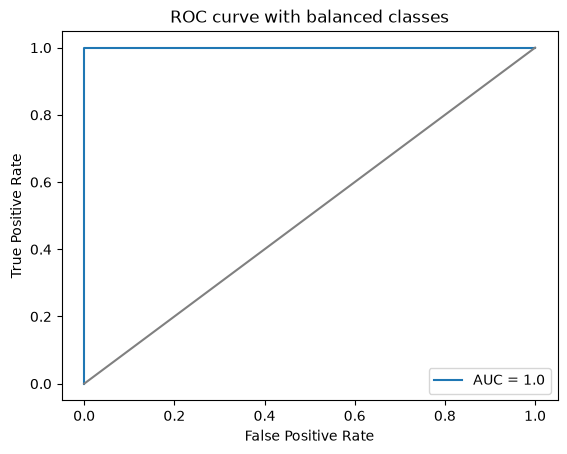

In [23]:
false_positive_rate, true_positive_rate, thresholds = roc_curve(y_train, balanced_probability)
area_under_curve = auc(false_positive_rate, true_positive_rate)
plt.plot(false_positive_rate, true_positive_rate, label='AUC = ' + f'{round(area_under_curve, 3)}')
plt.plot([0, 1], [0, 1], color='gray')
plt.legend()
plt.title('ROC curve with balanced classes')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

The case-control model with the 9 bending instances and intercept adjustment gives the same confusion matrix and AUC as the original. All 60 not-bending and 9 bending were correctly classified. Even though the classes were unbalanced, they were perfectly separated by the selected features which is why the rebalancing did not change outcomes.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [24]:
C_list = [0.01, 0.05, 0.1, 0.5, 1, 5, 10, 25, 50, 100]
l1_results = []
for l in range(1, 21):
    # training set only
    x, y = split_series(l, 'train')
    for C in C_list:
        per_fold_accuracy = []
        for train_index, value_index in folds.split(x, y):
            x_fold_train, x_fold_value = x.iloc[train_index], x.iloc[value_index]
            y_fold_train, y_fold_value = y[train_index], y[value_index]

            # scale as recommended by footnote 8
            scaler = StandardScaler()
            x_fold_train = scaler.fit_transform(x_fold_train)
            x_fold_value = scaler.transform(x_fold_value)

            l1_model = LogisticRegression(penalty='l1', C=C, max_iter=1000, solver='liblinear') # with liblinear
            l1_model.fit(x_fold_train, y_fold_train)
            predicted_class = l1_model.predict(x_fold_value)
            accuracy = accuracy_score(y_fold_value, predicted_class)
            per_fold_accuracy.append(accuracy)
        l1_results.append((l, C, np.mean(per_fold_accuracy)))

l1_results_df = pd.DataFrame(l1_results, columns=['l', 'C', 'cv_accuracy'])
l1_results_df.sort_values('cv_accuracy', ascending=False, inplace=True)
print(l1_results_df)

      l      C  cv_accuracy
194  20   1.00     0.985714
195  20   5.00     0.985714
196  20  10.00     0.985714
197  20  25.00     0.985714
185  19   5.00     0.985714
..   ..    ...          ...
170  18   0.01     0.870330
180  19   0.01     0.870330
181  19   0.05     0.870330
191  20   0.05     0.870330
190  20   0.01     0.870330

[200 rows x 3 columns]


In [25]:
print(l1_results_df.head(20))

      l      C  cv_accuracy
194  20    1.0     0.985714
195  20    5.0     0.985714
196  20   10.0     0.985714
197  20   25.0     0.985714
185  19    5.0     0.985714
198  20   50.0     0.985714
124  13    1.0     0.985714
6     1   10.0     0.971429
178  18   50.0     0.971429
175  18    5.0     0.971429
133  14    0.5     0.971429
116  12   10.0     0.971429
123  13    0.5     0.971429
125  13    5.0     0.971429
143  15    0.5     0.971429
193  20    0.5     0.971429
187  19   25.0     0.971429
188  19   50.0     0.971429
189  19  100.0     0.971429
179  18  100.0     0.971429


There are 7 pairs of 1 and C pairs which have a cross-validation accuracy of 0.985714.
I will pick the model with l=13, C=1.0 as it has the least features of the models tied for highest accuracy.

In [26]:
l1_best_l = 13
l1_best_C = 1.0

x_l1_train, y_l1_train = split_series(l1_best_l, 'train')
x_l1_test, y_l1_test = split_series(l1_best_l, 'test')

l1_scaler = StandardScaler()
x_l1_train_scaled = l1_scaler.fit_transform(x_l1_train)
x_l1_test_scaled = l1_scaler.transform(x_l1_test)

final_l1_model = LogisticRegression(penalty='l1', C=l1_best_C, max_iter=1000, solver='liblinear')
final_l1_model.fit(x_l1_train_scaled, y_l1_train)

l1_test_class = final_l1_model.predict(x_l1_test_scaled)
l1_test_accuracy = accuracy_score(y_l1_test, l1_test_class)
print('L1 accuracy on the test set:', l1_test_accuracy)

L1 accuracy on the test set: 0.9473684210526315


In [27]:
l1_pretty_test_confusion_matrix = pd.DataFrame(confusion_matrix(y_l1_test, l1_test_class), columns=['Predicted 0', 'Predicted 1'], index=['Actual 0 (Not bending)', 'Actual 1 (Bending)'])
l1_pretty_test_confusion_matrix.index.name = f'l* = {l1_best_l}, C* = {l1_best_C}'
l1_pretty_test_confusion_matrix

,Predicted 0,Predicted 1
"l* = 13, C* = 1.0",,
Actual 0 (Not bending),15,0
Actual 1 (Bending),1,3


In [28]:
l1_keep_columns = x_l1_train.columns[final_l1_model.coef_[0] != 0]
print('L1 Features:', len(l1_keep_columns))
print(l1_keep_columns)

L1 Features: 8
Index(['q3_avg_rss12_8', 'std_avg_rss13_3', 'q3_var_rss13_10',
       'mean_avg_rss23_2', 'mean_avg_rss23_4', 'mean_avg_rss23_12',
       'std_var_rss23_10', 'std_var_rss23_12'],
      dtype='str')


#### ii. Comparison

Variable selection using RFE performed better with a test accuracy of 100%, although the L1 penalized model came close with 94.7% accuracy. For the cross-validation test, RFE got 1.0 and L1 got 0.986 so they are approximately equal.
L1 was easier to implement because it only needed to adjust the C budget and then fit a model once. Using p-values and RFE required fitting multiple times to optimize both p and l.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [29]:
def multiclass_split_series(l, split_set):
    rows = []
    for (action, number), dataset in data.items():
        if train_test_split[(action, number)] != split_set:
            continue
        row = {'activity': action}
        for ts in time_series_only:
            l_pieces = np.array_split(dataset[ts], l)
            for i in range(l):
                piece = pd.Series(l_pieces[i])
                row[f'mean_{ts}_{i+1}'] = piece.mean()
                row[f'q3_{ts}_{i+1}'] = piece.quantile(0.75)
                row[f'std_{ts}_{i+1}'] = piece.std()
        rows.append(row)
    df = pd.DataFrame(rows)
    x = df.drop(columns=['activity'])
    y = df['activity'].values
    return x, y

In [42]:
max_l = 21
multi_results = []
for l in range(1, max_l):
    x, y = multiclass_split_series(l, 'train') # train set

    for C in C_list:
        per_fold_accuracy = []
        for train_index, value_index in folds.split(x, y):
            x_fold_train, x_fold_value = x.iloc[train_index], x.iloc[value_index]
            y_fold_train, y_fold_value = y[train_index], y[value_index]

            # scale as recommended by footnote 8
            scaler = StandardScaler()
            x_fold_train = scaler.fit_transform(x_fold_train)
            x_fold_value = scaler.transform(x_fold_value)

            multi_model = LogisticRegression(penalty='l1', C=C, max_iter=2000, solver='saga') # I found that saga can do this
            multi_model.fit(x_fold_train, y_fold_train)
            predicted_class = multi_model.predict(x_fold_value)
            accuracy = accuracy_score(y_fold_value, predicted_class)
            per_fold_accuracy.append(accuracy)
        multi_results.append((l, C, np.mean(per_fold_accuracy)))

multi_results_df = pd.DataFrame(multi_results, columns=['l', 'C', 'cv_accuracy'])
multi_results_df.sort_values('cv_accuracy', ascending=False, inplace=True)
print(multi_results_df.head(15))

    l      C  cv_accuracy
7   1   25.0     0.928571
5   1    5.0     0.928571
9   1  100.0     0.928571
8   1   50.0     0.928571
6   1   10.0     0.914286
14  2    1.0     0.898901
36  4   10.0     0.897802
4   1    1.0     0.883516
35  4    5.0     0.883516
16  2   10.0     0.883516
17  2   25.0     0.869231
15  2    5.0     0.869231
28  3   50.0     0.869231
29  3  100.0     0.869231
19  2  100.0     0.869231


There are 4 pairs of l and C pairs which have a cross-validation accuracy of 0.928571.
I am picking l=1 and C=5.0 as it is the one with the fewest features and highest penalty.

In [31]:
multi_best_l = 1
multi_best_C = 5.0

x_multi_train, y_multi_train = multiclass_split_series(multi_best_l, 'train')
x_multi_test, y_multi_test = multiclass_split_series(multi_best_l, 'test')

multi_scaler = StandardScaler()
x_multi_train_scaled = multi_scaler.fit_transform(x_multi_train)
x_multi_test_scaled = multi_scaler.transform(x_multi_test)

final_multi_model = LogisticRegression(penalty='l1', C=multi_best_C, max_iter=2000, solver='saga')
final_multi_model.fit(x_multi_train_scaled, y_multi_train)

multi_test_class = final_multi_model.predict(x_multi_test_scaled)
multi_test_accuracy = accuracy_score(y_multi_test, multi_test_class)
print('Test accuracy:', multi_test_accuracy)
print('Test error:', 1 - multi_test_accuracy)

Test accuracy: 0.9473684210526315
Test error: 0.052631578947368474


In [32]:
activity_names = final_multi_model.classes_

pretty_multi_confusion_matrix = pd.DataFrame(confusion_matrix(y_multi_test, multi_test_class, labels=activity_names), columns=['Predicted ' + name for name in activity_names], index=['Actual ' + name for name in activity_names]
)
pretty_multi_confusion_matrix.index.name = f'l* = {multi_best_l}, C* = {multi_best_C}'
pretty_multi_confusion_matrix

,Predicted bending1,Predicted bending2,Predicted cycling,Predicted lying,Predicted sitting,Predicted standing,Predicted walking
"l* = 1, C* = 5.0",,,,,,,
Actual bending1,2,0,0,0,0,0,0
Actual bending2,0,2,0,0,0,0,0
Actual cycling,0,0,3,0,0,0,0
Actual lying,0,0,0,3,0,0,0
Actual sitting,0,0,0,0,2,1,0
Actual standing,0,0,0,0,0,3,0
Actual walking,0,0,0,0,0,0,3


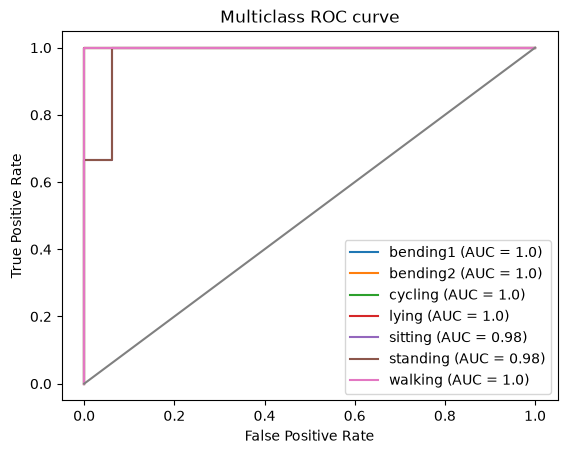

In [33]:
multi_test_probability = final_multi_model.predict_proba(x_multi_test_scaled)
y_multi_test_binary = label_binarize(y_multi_test, classes=activity_names)

for i, name in enumerate(activity_names):
    false_positive_rate, true_positive_rate, thresholds = roc_curve(y_multi_test_binary[:, i], multi_test_probability[:, i])
    area_under_curve = auc(false_positive_rate, true_positive_rate)
    plt.plot(false_positive_rate, true_positive_rate, label=f'{name} (AUC = {round(area_under_curve, 2)})')
plt.plot([0, 1], [0, 1], color='gray')
plt.legend()
plt.title('Multiclass ROC curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

The confusion matrix is done with one row/column per class for multiclass classification. ROC curves are one against the rest. This means that each class gets compared with every other class as a binary. So the plot ends up having a ROC curve line for each class (and separate AUC).

#### ii. Naive Bayes

In [34]:
naive_bayes_results = []

for l in range(1, 21):
    x, y = multiclass_split_series(l, 'train')

    for type_of_model in ['Gaussian', 'Multinomial']:
        per_fold_accuracy = []

        for train_index, value_index in folds.split(x, y):
            x_fold_train, x_fold_value = x.iloc[train_index], x.iloc[value_index]
            y_fold_train, y_fold_value = y[train_index], y[value_index]
            # no scaler
            naive_bayes_model = ''
            if type_of_model == 'Gaussian':
                naive_bayes_model = GaussianNB()
            elif type_of_model == 'Multinomial':
                naive_bayes_model = MultinomialNB()
            naive_bayes_model.fit(x_fold_train, y_fold_train)
            predicted_class = naive_bayes_model.predict(x_fold_value)
            accuracy = accuracy_score(y_fold_value, predicted_class)
            per_fold_accuracy.append(accuracy)
        naive_bayes_results.append((type_of_model, l, np.mean(per_fold_accuracy)))
naive_bayes_results_df = pd.DataFrame(naive_bayes_results, columns=['model', 'l', 'cv_accuracy'])
naive_bayes_results_df.sort_values('cv_accuracy', ascending=False, inplace=True)

print(naive_bayes_results_df[naive_bayes_results_df['model'] == 'Gaussian'].head(10))
print(naive_bayes_results_df[naive_bayes_results_df['model'] == 'Multinomial'].head(10))

       model   l  cv_accuracy
12  Gaussian   7     0.884615
0   Gaussian   1     0.869231
10  Gaussian   6     0.841758
16  Gaussian   9     0.840659
2   Gaussian   2     0.839560
18  Gaussian  10     0.827473
22  Gaussian  12     0.826374
6   Gaussian   4     0.825275
34  Gaussian  18     0.812088
8   Gaussian   5     0.810989
          model   l  cv_accuracy
1   Multinomial   1     0.898901
9   Multinomial   5     0.868132
5   Multinomial   3     0.854945
3   Multinomial   2     0.853846
11  Multinomial   6     0.840659
13  Multinomial   7     0.840659
7   Multinomial   4     0.839560
15  Multinomial   8     0.839560
27  Multinomial  14     0.826374
25  Multinomial  13     0.812088


In [35]:
gaussian_best_l = 7

x_gaussian_train, y_gaussian_train = multiclass_split_series(gaussian_best_l, 'train')
x_gaussian_test, y_gaussian_test = multiclass_split_series(gaussian_best_l, 'test')
gaussian_model = GaussianNB()
gaussian_model.fit(x_gaussian_train, y_gaussian_train)
gaussian_test_class = gaussian_model.predict(x_gaussian_test)
gaussian_test_accuracy = accuracy_score(y_gaussian_test, gaussian_test_class)
print('Gaussian')
print('Test accuracy:', gaussian_test_accuracy)
print('Test error:', 1 - gaussian_test_accuracy)

Gaussian
Test accuracy: 0.7894736842105263
Test error: 0.21052631578947367


In [36]:
gaussian_names = gaussian_model.classes_
gcm = confusion_matrix(y_gaussian_test, gaussian_test_class, labels=gaussian_names)
pretty_gaussian_confusion_matrix = pd.DataFrame(gcm, columns=['Predicted ' + name for name in gaussian_names], index=['Actual ' + name for name in gaussian_names])
pretty_gaussian_confusion_matrix.index.name = f'Gaussian, l* = {gaussian_best_l}'
pretty_gaussian_confusion_matrix

,Predicted bending1,Predicted bending2,Predicted cycling,Predicted lying,Predicted sitting,Predicted standing,Predicted walking
"Gaussian, l* = 7",,,,,,,
Actual bending1,2,0,0,0,0,0,0
Actual bending2,0,1,0,0,1,0,0
Actual cycling,0,0,3,0,0,0,0
Actual lying,0,0,0,2,1,0,0
Actual sitting,0,0,0,0,2,1,0
Actual standing,0,0,0,0,1,2,0
Actual walking,0,0,0,0,0,0,3


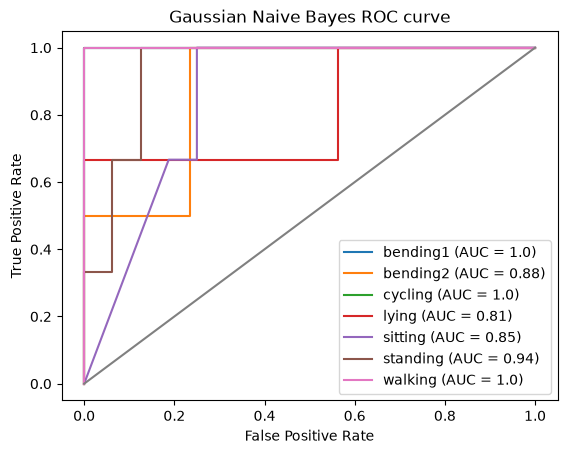

In [37]:
gaussian_test_probability = gaussian_model.predict_proba(x_gaussian_test)
y_gaussian_test_binary = label_binarize(y_gaussian_test, classes=gaussian_names)
for i, name in enumerate(gaussian_names):
    false_positive_rate, true_positive_rate, thresholds = roc_curve(y_gaussian_test_binary[:, i], gaussian_test_probability[:, i])
    area_under_curve = auc(false_positive_rate, true_positive_rate)
    plt.plot(false_positive_rate, true_positive_rate, label=f'{name} (AUC = {round(area_under_curve, 2)})')
plt.plot([0, 1], [0, 1], color='gray')
plt.legend()
plt.title('Gaussian Naive Bayes ROC curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

In [38]:
multinomial_best_l = 1

x_multinomial_train, y_multinomial_train = multiclass_split_series(multinomial_best_l, 'train')
x_multinomial_test, y_multinomial_test = multiclass_split_series(multinomial_best_l, 'test')
multinomial_model = MultinomialNB()
multinomial_model.fit(x_multinomial_train, y_multinomial_train)
multinomial_test_class = multinomial_model.predict(x_multinomial_test)
multinomial_test_accuracy = accuracy_score(y_multinomial_test, multinomial_test_class)
print('Multinomial')
print('Test accuracy:', multinomial_test_accuracy)
print('Test error:', 1 - multinomial_test_accuracy)

Multinomial
Test accuracy: 0.8421052631578947
Test error: 0.1578947368421053


In [39]:
multinomial_names = multinomial_model.classes_
mcm = confusion_matrix(y_multinomial_test, multinomial_test_class, labels=multinomial_names)
pretty_multinomial_confusion_matrix = pd.DataFrame(mcm, columns=['Predicted ' + name for name in multinomial_names], index=['Actual ' + name for name in multinomial_names])
pretty_multinomial_confusion_matrix.index.name = f'Multinomial, l* = {multinomial_best_l}'
pretty_multinomial_confusion_matrix

,Predicted bending1,Predicted bending2,Predicted cycling,Predicted lying,Predicted sitting,Predicted standing,Predicted walking
"Multinomial, l* = 1",,,,,,,
Actual bending1,2,0,0,0,0,0,0
Actual bending2,1,1,0,0,0,0,0
Actual cycling,0,0,3,0,0,0,0
Actual lying,0,0,0,3,0,0,0
Actual sitting,0,0,0,0,2,1,0
Actual standing,0,0,0,1,0,2,0
Actual walking,0,0,0,0,0,0,3


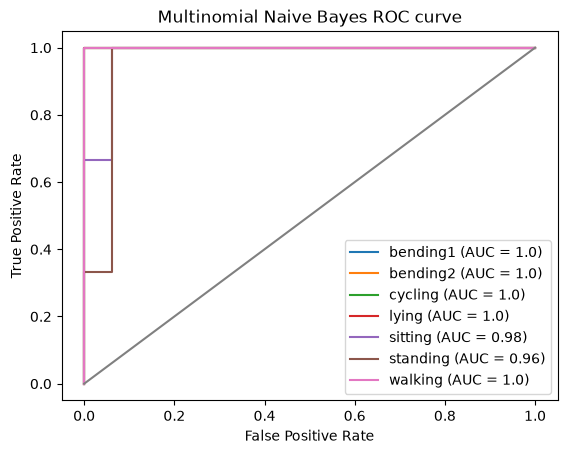

In [40]:
multinomial_test_probability = multinomial_model.predict_proba(x_multinomial_test)
y_multinomial_test_binary = label_binarize(y_multinomial_test, classes=multinomial_names)
for i, name in enumerate(multinomial_names):
    false_positive_rate, true_positive_rate, thresholds = roc_curve(y_multinomial_test_binary[:, i], multinomial_test_probability[:, i])
    area_under_curve = auc(false_positive_rate, true_positive_rate)
    plt.plot(false_positive_rate, true_positive_rate, label=f'{name} (AUC = {round(area_under_curve, 2)})')
plt.plot([0, 1], [0, 1], color='gray')
plt.legend()
plt.title('Multinomial Naive Bayes ROC curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

#### iii. Comparison

The L1 multiclass regression performed the best with 0.0526 test error, followed by multinomial Naive Bayes' with 0.158 test error. Gaussian Naive Bayes performed the worst with a test error of 0.211.
All three of the models made the error of mistaking sitting as standing. Interestingly there aren't any mistakes on the more active activities (cycling and walking). Maybe their cyclical motion pattern makes them easier to recognize than a less mobile activity.

## 3. ISLR 4.8.3

There are k classes and only one feature (p=1) so equation 4.16 from ISLR is applicable.

$f_{k}(x)=\frac{1}{\sqrt{2\pi}\sigma_{k}}exp(-\frac{1}{2\sigma_{k}^{2}}(x-\mu_{k})^{2})$

Since the denominator of $p_k(x)$ from equation 4.17 will be the same for every class, the Bayes classifier needs to maximize $\pi_kf_k(x)$.

$\pi_kf_k(x)=\pi_k\frac{1}{\sqrt{2\pi}\sigma_{k}}exp(-\frac{1}{2\sigma_{k}^{2}}(x-\mu_{k})^{2})$

Natural log to get rid of the e
$ln(\pi_kf_k(x))=ln(\pi_k)+ln(\frac{1}{\sqrt{2\pi}\sigma_{k}}) + ln(exp(-\frac{1}{2\sigma_{k}^{2}}(x-\mu_{k})^{2}))$

$ln(\pi_kf_k(x))=ln(\pi_k)+ln(\frac{1}{\sqrt{2\pi}\sigma_{k}}) + -\frac{1}{2\sigma_{k}^{2}}(x-\mu_{k})^{2}$

$\delta_{k}=ln(\pi_k)+ln(\frac{1}{\sqrt{2\pi}\sigma_{k}}) -\frac{1}{2\sigma_{k}^{2}}x^{2} + \frac{\mu_{k}}{\sigma_{k}^{2}}x-\frac{\mu_k^{2}}{2\sigma_{k}^{2}}$

At this point, it can be concluded that the Bayes classifier is not linear as there is an $x^2$ and $x$ term. The coefficient of $x^2$ depends on k so it cannot cancel when comparing two classes. That is why the Bayes classifer is a quadratic.

## 4. ISLR 4.8.7

$Pr(Y = k | X = x) = \frac{\pi_{k}f_{k}(x))}{\sum_{l=1}^{K}\pi_{l}f_{l}(x))}$ (ISLR 4.15)

$f(x) = \frac{1}{\sqrt{2\pi\sigma^{2}}}e^{-\frac{(x-\mu)^{2})}{2\sigma^{2}}}$ (given)

Y = Yes

Given:

Y = Yes μ1 = 10, π1 = 0.8, X = 10

Y = No, μ2 = 0, π2 = 0.2, X = 0

Variance = 36

X = 4

$Pr(Y = k | X = x) = \frac{\pi_{k}\frac{1}{\sqrt{2\pi\sigma^{2}}}e^{-\frac{(x-\mu)^{2}}{2\sigma^{2}}}}{\pi_{k}\frac{1}{\sqrt{2\pi\sigma^{2}}}e^{-\frac{(x-\mu)^{2}}{2\sigma^{2}}} + \pi_{k}\frac{1}{\sqrt{2\pi\sigma^{2}}}e^{-\frac{(x-\mu)^{2}}{2\sigma^{2}}}}$

$Pr(Y = k | X = x) = \frac{\pi_{1}\frac{1}{\sqrt{2\pi\sigma^{2}}}e^{-\frac{(x-\mu_{1})^{2}}{2\sigma^{2}}}}{\pi_{1}\frac{1}{\sqrt{2\pi\sigma^{2}}}e^{-\frac{(x-\mu_{1})^{2}}{2\sigma^{2}}} + \pi_{2}\frac{1}{\sqrt{2\pi\sigma^{2}}}e^{-\frac{(x-\mu_{2})^{2}}{2\sigma^{2}}}}$

$Pr(Y = k | X = x) = \frac{\pi_{1}e^{-\frac{(x-\mu_{1})^{2}}{2\sigma^{2}}}}{\pi_{1}e^{-\frac{(x-\mu_{1})^{2}}{2\sigma^{2}}} + \pi_{2}e^{-\frac{(x-\mu_{2})^{2}}{2\sigma^{2}}}}$

$Pr(Y = Yes | X = 4) = \frac{0.8e^{-\frac{(4-10)^{2}}{2 * 36}}}{0.8e^{-\frac{(4-10)^{2}}{2*36}} + 0.2e^{-\frac{(4-0)^{2}}{2*36}}}$

$Pr(Y = Yes | X = 4) = 0.751852$

Resource used for writing LaTeX:

https://latexeditor.lagrida.com/

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9